This notebook shows the discrimination power of the likelihood metric against the current chi2 at particle identification

In [13]:
import numpy as np
import math
import pickle
import pandas as pd
import uproot as uproot
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
# from analysis_village.plot_style import sbnd_style

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)



In [2]:
with pd.HDFStore("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/output_MC_collab_LL.df", mode="r") as store:
    keys = store.keys()
    print(keys)

['/evt_0', '/hdr_0', '/histgenevtdf_0', '/histpotdf_0', '/mcnu_0', '/pot_0', '/split']


In [14]:
df = pd.read_hdf("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/output_MC_largeTest_LL.df", key='/evt_0')
# # df = df[df["total_nhits_proton"] > 14]
# muondf = df[np.abs(df["truth_pdg"]) == 13]
# piondf = df[np.abs(df["truth_pdg"]) == 211]
# protondf = df[df["truth_pdg"] == 2212]
df = df[df["slc", "is_clear_cosmic"] == 0]
df = df[df["pfp", "trk", "truth", "p", "cont_tpc"] == 1]


/tmp/ipykernel_1150730/3408046138.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  df = df[df["slc", "is_clear_cosmic"] == 0]
/tmp/ipykernel_1150730/3408046138.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  df = df[df["pfp", "trk", "truth", "p", "cont_tpc"] == 1]


In [3]:
df.head()

slc  \
                                                      is_clear_cosmic   
                                                                        
                                                                        
                                                                        
                                                                        
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                   
1        1     0              0                                     0   
                              1                                     0   
         3     0              0                                     0   
                              1                                     0   
         4     0              0                                     0   

                                                                              \
                                                          vertex               
                                                               x           y   
                                                                               
                                                                               
                                                                               
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                          
1        1     0              0                       -68.975815  124.859596   
                              1                       -68.975815  124.859596   
         3     0              0                       -52.697365    4.298021   
                              1                       -52.697365    4.298021   
         4     0              0                       -46.268570 -186.258606   

                                                                        \
                                                                  self   
                                                                z        
                                                                         
                                                                         
                                                                         
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                    
1        1     0              0                        217.167191   73   
                              1                        217.167191   73   
         3     0              0                        399.908264   28   
                              1                        399.908264   28   
         4     0              0                        148.239227   39   

                                                                               \
                                                         tmatch                 
                                                            eff       pur idx   
                                                                                
                                                                                
                                                                                
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                           
1        1     0              0                        0.980509  0.560783   0   
                              1                        0.980509  0.560783   0   
         3     0              0                        0.656768  0.876566   1   
                              1                        0.656768  0.876566   1   
         4     0              0                        0.967384  0.665963   0   

                                                                              \
                                                      producer          nuid   
                                                               crlongtrkdiry   
                                                                               
                                              

In [15]:
p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]
print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")


Protons: 7086, Muons: 1789, Pions: 942


/tmp/ipykernel_1150730/556601378.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
/tmp/ipykernel_1150730/556601378.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
/tmp/ipykernel_1150730/556601378.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]


/tmp/ipykernel_1150730/3593872833.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:12: PerformanceWarning: indexing past lexsort depth may impact perfor

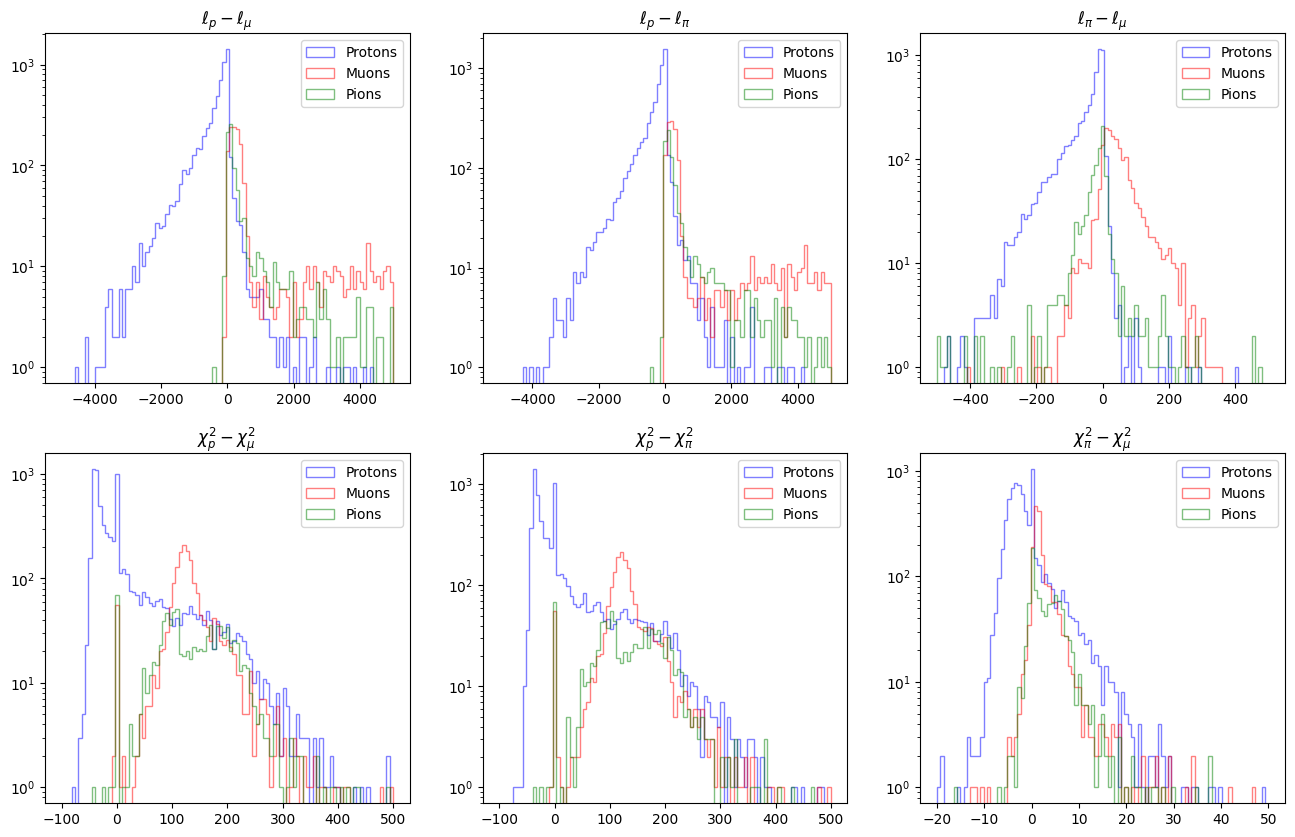

In [17]:
fig, ax = plt.subplots(2,3, figsize=(16, 10))
ax = ax.flatten()
log=True

ax[0].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[0].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[0].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[0].legend()
ax[0].set_title(f"$\ell_p - \ell_\mu$ ")


ax[1].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[1].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[1].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[1].legend()
ax[1].set_title(f"$\ell_p - \ell_\pi$ ")


ax[2].hist(p_df["pfp", "trk", "llpid", "ell_pi"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[2].hist(mu_df["pfp", "trk", "llpid", "ell_pi"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[2].hist(pi_df["pfp", "trk", "llpid", "ell_pi"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[2].legend()
ax[2].set_title(f"$\ell_\pi - \ell_\mu$ ")


ax[3].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - p_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[3].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[3].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[3].legend()
ax[3].set_title(f"$\chi^2_p - \chi^2_\mu$ ")

ax[4].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - p_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[4].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[4].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[4].legend()
ax[4].set_title(f"$\chi^2_p - \chi^2_\pi$ ")

ax[5].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - p_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[5].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[5].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[5].legend()
ax[5].set_title(f"$\chi^2_\pi - \chi^2_\mu$ ")

if log:
    for i in range(6):
        ax[i].set_yscale('log')
plt.show()  

/tmp/ipykernel_1150730/2263204449.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Blues')
/tmp/ipykernel_1150730/2263204449.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Reds')
/tmp/ipykernel_1150730/2263204449.py:14: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[2].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Greens')
/tmp/ipykernel_1150730/2263204449.py:19: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[3].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2

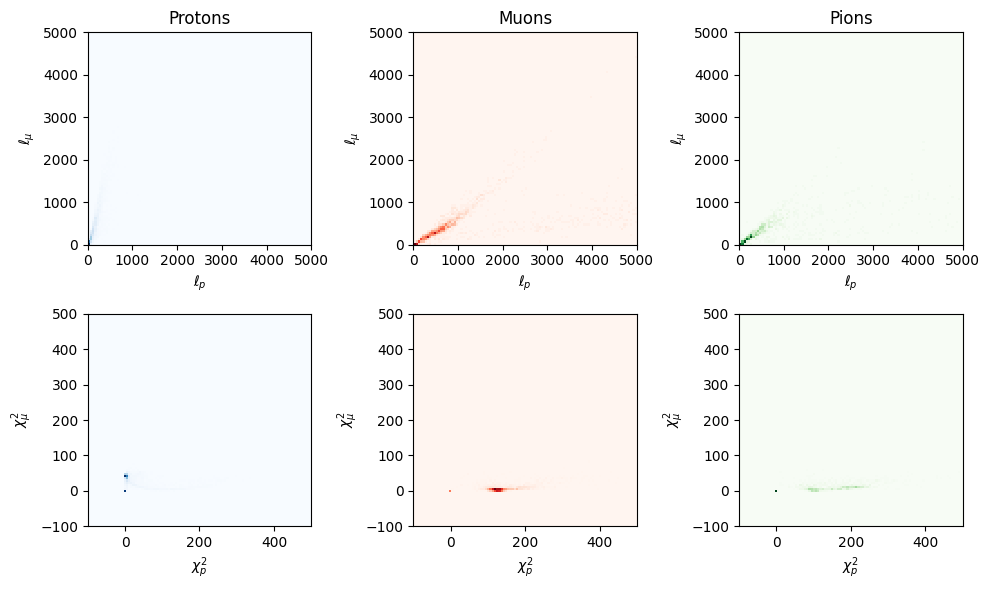

In [18]:
fig, ax = plt.subplots(2,3,figsize=(10, 6))
ax=ax.flatten()

ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Blues')
ax[0].set_xlabel("$\ell_p$")
ax[0].set_ylabel("$\ell_\mu$")
ax[0].set_title("Protons")

ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Reds')
ax[1].set_xlabel("$\ell_p$")
ax[1].set_ylabel("$\ell_\mu$")
ax[1].set_title("Muons")

ax[2].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Greens')
ax[2].set_xlabel("$\ell_p$")
ax[2].set_ylabel("$\ell_\mu$")
ax[2].set_title("Pions")

ax[3].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Blues')
ax[3].set_xlabel("$\chi^2_p$")
ax[3].set_ylabel("$\chi^2_\mu$")

ax[4].hist2d(mu_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], mu_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Reds')
ax[4].set_xlabel("$\chi^2_p$")
ax[4].set_ylabel("$\chi^2_\mu$")
ax[5].hist2d(pi_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], pi_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Greens')
ax[5].set_xlabel("$\chi^2_p$")
ax[5].set_ylabel("$\chi^2_\mu$")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1150730/1689864628.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:15: PerformanceWarning: indexing past lexsort depth may impact

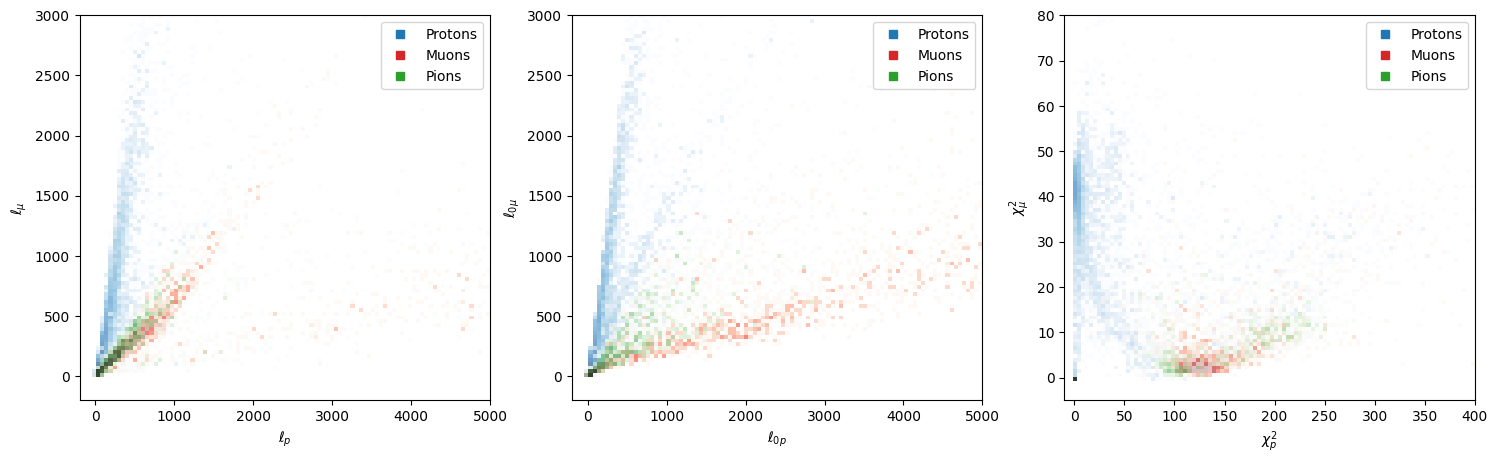

In [19]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(1,3,figsize=(18, 5))

ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].plot([], [], 's', color='tab:blue', label='Protons')
ax[0].plot([], [], 's', color='tab:red', label='Muons')
ax[0].plot([], [], 's', color='tab:green', label='Pions')
ax[0].legend()
ax[0].set_xlabel("$\ell_p$")
ax[0].set_ylabel("$\ell_\mu$")

ax[1].hist2d(p_df["pfp", "trk", "llpid", "ell0_p"], p_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell0_p"], mu_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].hist2d(pi_df["pfp", "trk", "llpid", "ell0_p"], pi_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].plot([], [], 's', color='tab:blue', label='Protons')
ax[1].plot([], [], 's', color='tab:red', label='Muons')
ax[1].plot([], [], 's', color='tab:green', label='Pions')
ax[1].legend()
ax[1].set_xlabel("$\ell_{0p}$")
ax[1].set_ylabel("$\ell_{0\mu}$")


ax[2].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].hist2d(mu_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], mu_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].hist2d(pi_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], pi_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].plot([], [], 's', color='tab:blue', label='Protons')
ax[2].plot([], [], 's', color='tab:red', label='Muons')
ax[2].plot([], [], 's', color='tab:green', label='Pions')
ax[2].legend()
ax[2].set_xlabel("$\chi^2_p$")
ax[2].set_ylabel("$\chi^2_\mu$")

# plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1937425854.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_ok  = p_df[p_df["pfp", "trk", "llpid", "ell_mu"].notna() & (p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_ok = mu_df[mu_df["pfp", "trk", "llpid", "ell_mu"].notna() & (mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_ok = pi_df[pi_df["pfp", "trk", "llpid", "ell_mu"].notna() & (pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_mu"]
/tmp/ipykernel_1150730/1937425854.py:10: PerformanceWarning: indexing past lexsort depth may impact perform

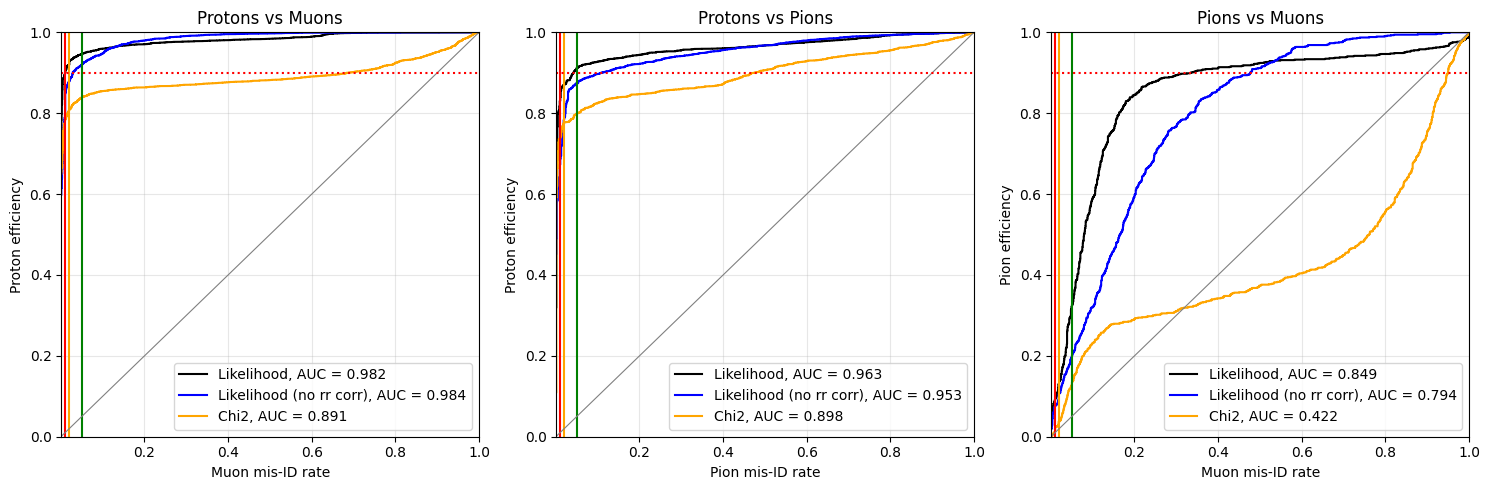

In [30]:
# only keep tracks where both the likelihood and the chi2 worked
p_ok  = p_df[p_df["pfp", "trk", "llpid", "ell_mu"].notna() & (p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
mu_ok = mu_df[mu_df["pfp", "trk", "llpid", "ell_mu"].notna() & (mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
pi_ok = pi_df[pi_df["pfp", "trk", "llpid", "ell_mu"].notna() & (pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]

fig, ax = plt.subplots(1,3,figsize=(15, 5))

# Protons vs Muons, likelihood
sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell_p"] - mu_ok["pfp", "trk", "llpid", "ell_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
# Protons vs Muons, likelihood0
sig = p_ok["pfp", "trk", "llpid", "ell0_p"] - p_ok["pfp", "trk", "llpid", "ell0_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell0_p"] - mu_ok["pfp", "trk", "llpid", "ell0_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Protons vs Muons, chi2
sig = p_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - p_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
bkg = mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[0].set_title("Protons vs Muons")
ax[0].set_xlabel("Muon mis-ID rate")
ax[0].set_ylabel("Proton efficiency")
ax[0].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])


# Protons vs Pions, likelihood
sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_pi"]
bkg = pi_ok["pfp", "trk", "llpid", "ell_p"] - pi_ok["pfp", "trk", "llpid", "ell_pi"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

sig = p_ok["pfp", "trk", "llpid", "ell0_p"] - p_ok["pfp", "trk", "llpid", "ell0_pi"]
bkg = pi_ok["pfp", "trk", "llpid", "ell0_p"] - pi_ok["pfp", "trk", "llpid", "ell0_pi"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Protons vs Pions, chi2
sig = p_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - p_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"]
bkg = pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[1].set_title("Protons vs Pions")
ax[1].set_xlabel("Pion mis-ID rate")
ax[1].set_ylabel("Proton efficiency")
ax[1].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])

# Pions vs Muons, likelihood
sig = pi_ok["pfp", "trk", "llpid", "ell_pi"] - pi_ok["pfp", "trk", "llpid", "ell_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell_pi"] - mu_ok["pfp", "trk", "llpid", "ell_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

sig = pi_ok["pfp", "trk", "llpid", "ell0_pi"] - pi_ok["pfp", "trk", "llpid", "ell0_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell0_pi"] - mu_ok["pfp", "trk", "llpid", "ell0_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Pions vs Muons, chi2
sig = pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"] - pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
bkg = mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"] - mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[2].set_title("Pions vs Muons")
ax[2].set_xlabel("Muon mis-ID rate")
ax[2].set_ylabel("Pion efficiency")
ax[2].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])

for k in range(3):
    ax[k].plot([0, 1], [0, 1], color='gray', linewidth=0.8)
    ax[k].axhline(0.9, color='red', linestyle=':')
    ax[k].set_xlim(0.001, 1)
    # ax[k].set_xscale("log")
    ax[k].set_ylim(0, 1)
    ax[k].grid(alpha=0.3)
    ax[k].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1530449805.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_ll_bad   = p_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_chi_bad  = p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
/tmp/ipykernel_1150730/1530449805.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_ll_bad  = mu_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_chi_bad = mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
/tmp/ipykernel_1150730/1530449805.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_ll_bad  = pi_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_chi_

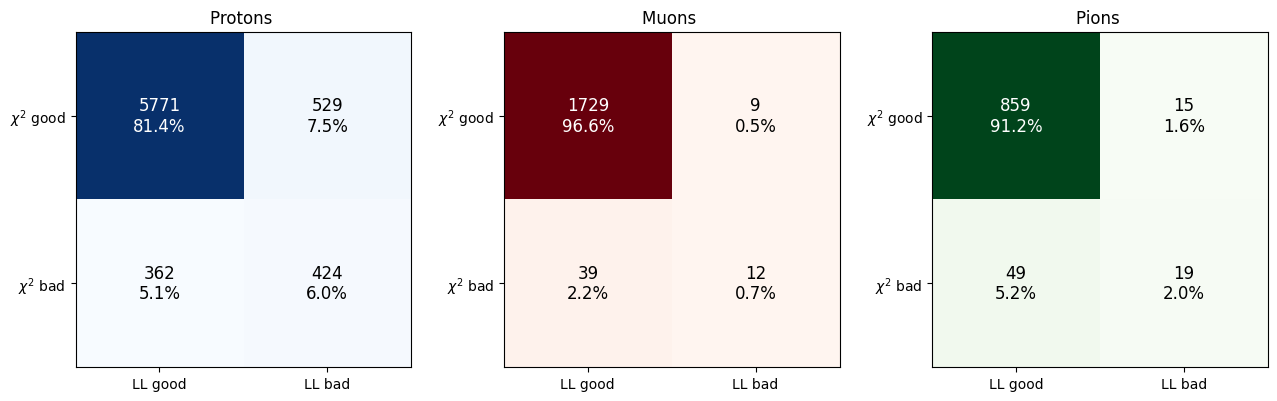

In [31]:
# True = that PID failed for this track
p_ll_bad   = p_df["pfp", "trk", "llpid", "ell_mu"].isna()
p_chi_bad  = p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
mu_ll_bad  = mu_df["pfp", "trk", "llpid", "ell_mu"].isna()
mu_chi_bad = mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
pi_ll_bad  = pi_df["pfp", "trk", "llpid", "ell_mu"].isna()
pi_chi_bad = pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0

# rows = chi2 (good, bad), columns = llpid (good, bad)
p_mat  = np.array([[np.sum(~p_chi_bad & ~p_ll_bad),   np.sum(~p_chi_bad & p_ll_bad)],
                   [np.sum(p_chi_bad & ~p_ll_bad),    np.sum(p_chi_bad & p_ll_bad)]])
mu_mat = np.array([[np.sum(~mu_chi_bad & ~mu_ll_bad), np.sum(~mu_chi_bad & mu_ll_bad)],
                   [np.sum(mu_chi_bad & ~mu_ll_bad),  np.sum(mu_chi_bad & mu_ll_bad)]])
pi_mat = np.array([[np.sum(~pi_chi_bad & ~pi_ll_bad), np.sum(~pi_chi_bad & pi_ll_bad)],
                   [np.sum(pi_chi_bad & ~pi_ll_bad),  np.sum(pi_chi_bad & pi_ll_bad)]])

fig, ax = plt.subplots(1,3,figsize=(13, 4))

ax[0].imshow(p_mat, cmap='Blues')
ax[0].set_title(f"Protons ")
ax[1].imshow(mu_mat, cmap='Reds')
ax[1].set_title(f"Muons ")
ax[2].imshow(pi_mat, cmap='Greens')
ax[2].set_title(f"Pions ")

for k, mat in enumerate([p_mat, mu_mat, pi_mat]):
    for i in range(2):
        for j in range(2):
            ax[k].text(j, i, f"{mat[i, j]}\n{100 * mat[i, j] / mat.sum():.1f}%", ha='center', va='center', fontsize=12, color='white' if mat[i, j] > mat.max() / 2 else 'black')
    ax[k].set_xticks([0, 1])
    ax[k].set_xticklabels(["LL good", "LL bad"])
    ax[k].set_yticks([0, 1])
    ax[k].set_yticklabels(["$\\chi^2$ good", "$\\chi^2$ bad"])

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/2452625986.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_cont = p_df[(p_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & p_df["pfp", "trk", "llpid", "ell_p"].notna()]
/tmp/ipykernel_1150730/2452625986.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_true = (p_cont["pfp", "trk", "truth", "p", "startE"] - m_p) * 1000  # MeV
/tmp/ipykernel_1150730/2452625986.py:12: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_range = p_cont["pfp", "trk", "rangeP", "p_proton"]
/tmp/ipykernel_1150730/2452625986.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_corr = np.interp(p_cont["pfp", "trk", "len"] + p_cont["pfp", "trk", "llpid", "dl_p"], table["range"], table["ke"])  # MeV
/tmp/ipykernel_1150730/2452625986.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  stopped = p_cont["pfp", "trk", "truth", "p", "end_process"

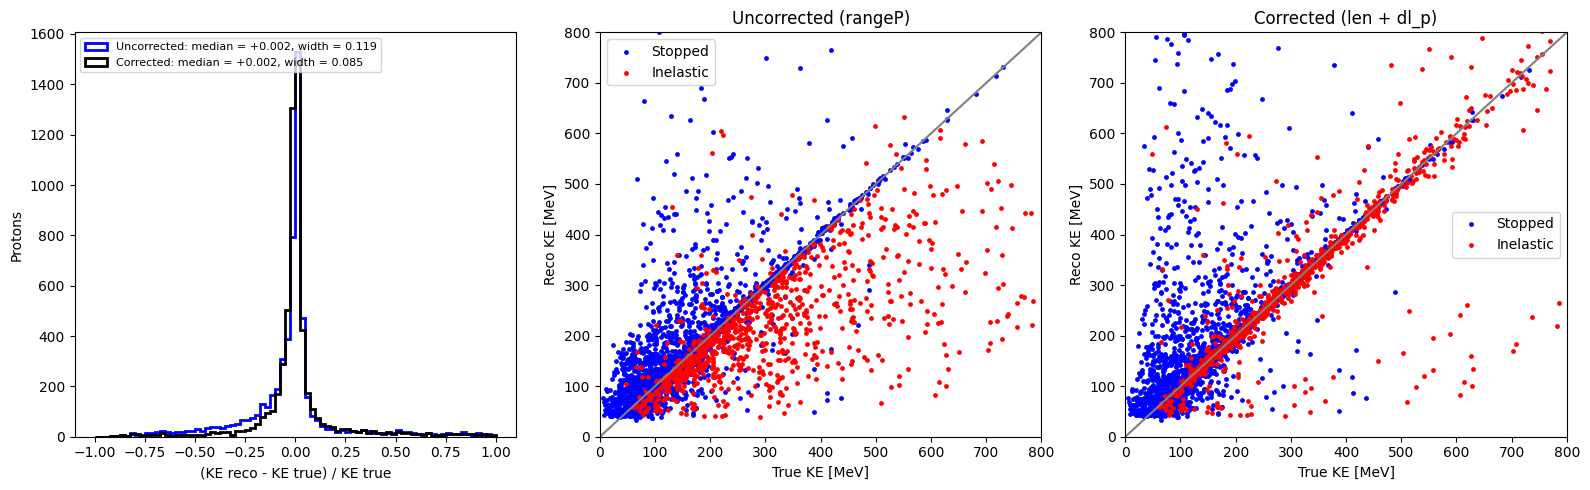

In [22]:
from makedf import llpid

# true protons that are contained in the TPC and have a likelihood fit
p_cont = p_df[(p_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & p_df["pfp", "trk", "llpid", "ell_p"].notna()]

m_p = 0.938272  # GeV

# true KE
ke_true = (p_cont["pfp", "trk", "truth", "p", "startE"] - m_p) * 1000  # MeV

# uncorrected: CAF range momentum
p_range = p_cont["pfp", "trk", "rangeP", "p_proton"]
ke_uncorr = (np.sqrt(p_range**2 + m_p**2) - m_p) * 1000  # MeV

# corrected: range = reco length + dl_p, turned into KE with the llpid range table
table = llpid._ke_table("p")
ke_corr = np.interp(p_cont["pfp", "trk", "len"] + p_cont["pfp", "trk", "llpid", "dl_p"], table["range"], table["ke"])  # MeV

res_uncorr = (ke_uncorr - ke_true) / ke_true
res_corr = (ke_corr - ke_true) / ke_true

# how the true proton ended
stopped = p_cont["pfp", "trk", "truth", "p", "end_process"] == 54   # hIoni: ranged out and stopped
inel    = p_cont["pfp", "trk", "truth", "p", "end_process"] == 7    # protonInelastic: interacted before stopping

fig, ax = plt.subplots(1,3,figsize=(16, 5))

ax[0].hist(res_uncorr, bins=np.linspace(-1, 1, 81), histtype='step', linewidth=2, color='blue', label=f"Uncorrected: median = {np.median(res_uncorr):+.3f}, width = {(np.percentile(res_uncorr, 84) - np.percentile(res_uncorr, 16)) / 2:.3f}")
ax[0].hist(res_corr, bins=np.linspace(-1, 1, 81), histtype='step', linewidth=2, color='black', label=f"Corrected: median = {np.median(res_corr):+.3f}, width = {(np.percentile(res_corr, 84) - np.percentile(res_corr, 16)) / 2:.3f}")
ax[0].set_xlabel("(KE reco - KE true) / KE true")
ax[0].set_ylabel("Protons")
ax[0].legend(loc='upper left', fontsize=8)

ax[1].scatter(ke_true[stopped], ke_uncorr[stopped], s=6, color='blue', label="Stopped")
ax[1].scatter(ke_true[inel], ke_uncorr[inel], s=6, color='red', label="Inelastic")
ax[1].plot([0, 800], [0, 800], color='gray')
ax[1].set_xlim(0, 800)
ax[1].set_ylim(0, 800)
ax[1].set_xlabel("True KE [MeV]")
ax[1].set_ylabel("Reco KE [MeV]")
ax[1].set_title("Uncorrected (rangeP)")
ax[1].legend()

ax[2].scatter(ke_true[stopped], ke_corr[stopped], s=6, color='blue', label="Stopped")
ax[2].scatter(ke_true[inel], ke_corr[inel], s=6, color='red', label="Inelastic")
ax[2].plot([0, 800], [0, 800], color='gray')
ax[2].set_xlim(0, 800)
ax[2].set_ylim(0, 800)
ax[2].set_xlabel("True KE [MeV]")
ax[2].set_ylabel("Reco KE [MeV]")
ax[2].set_title("Corrected (len + dl_p)")
ax[2].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1929644183.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_cont = pi_df[(pi_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & pi_df["pfp", "trk", "llpid", "ell_pi"].notna()]
/tmp/ipykernel_1150730/1929644183.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_true = (pi_cont["pfp", "trk", "truth", "p", "startE"] - m_pi) * 1000  # MeV
/tmp/ipykernel_1150730/1929644183.py:12: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_range = pi_cont["pfp", "trk", "rangeP", "p_pion"]
/tmp/ipykernel_1150730/1929644183.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_corr = np.interp(pi_cont["pfp", "trk", "len"] + pi_cont["pfp", "trk", "llpid", "dl_pi"], table["range"], table["ke"])  # MeV
/tmp/ipykernel_1150730/1929644183.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  stopped = (pi_cont["pfp", "trk", "truth", "p", "e

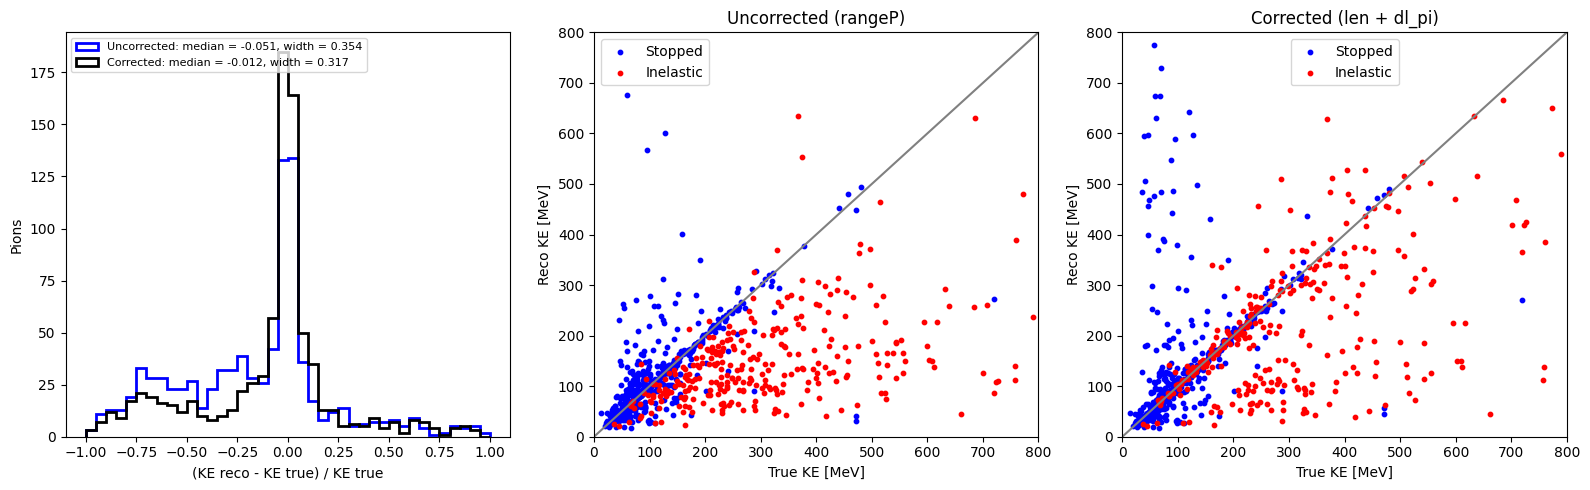

In [23]:
from makedf import llpid

# true pions that are contained in the TPC and have a likelihood fit
pi_cont = pi_df[(pi_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & pi_df["pfp", "trk", "llpid", "ell_pi"].notna()]

m_pi = 0.13957039  # GeV

# true KE
ke_true = (pi_cont["pfp", "trk", "truth", "p", "startE"] - m_pi) * 1000  # MeV

# uncorrected: CAF range momentum
p_range = pi_cont["pfp", "trk", "rangeP", "p_pion"]
ke_uncorr = (np.sqrt(p_range**2 + m_pi**2) - m_pi) * 1000  # MeV

# corrected: range = reco length + dl_pi, turned into KE with the llpid range table
table = llpid._ke_table("pi")
ke_corr = np.interp(pi_cont["pfp", "trk", "len"] + pi_cont["pfp", "trk", "llpid", "dl_pi"], table["range"], table["ke"])  # MeV

res_uncorr = (ke_uncorr - ke_true) / ke_true
res_corr = (ke_corr - ke_true) / ke_true

# how the true pion ended
stopped = (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 3) | (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 45)   # Decay or CaptureAtRest: stopped
inel    = (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 9) | (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 10)   # pi+/pi- Inelastic: interacted before stopping

fig, ax = plt.subplots(1,3,figsize=(16, 5))

ax[0].hist(res_uncorr, bins=np.linspace(-1, 1, 41), histtype='step', linewidth=2, color='blue', label=f"Uncorrected: median = {np.median(res_uncorr):+.3f}, width = {(np.percentile(res_uncorr, 84) - np.percentile(res_uncorr, 16)) / 2:.3f}")
ax[0].hist(res_corr, bins=np.linspace(-1, 1, 41), histtype='step', linewidth=2, color='black', label=f"Corrected: median = {np.median(res_corr):+.3f}, width = {(np.percentile(res_corr, 84) - np.percentile(res_corr, 16)) / 2:.3f}")
ax[0].set_xlabel("(KE reco - KE true) / KE true")
ax[0].set_ylabel("Pions")
ax[0].legend(loc='upper left', fontsize=8)

ax[1].scatter(ke_true[stopped], ke_uncorr[stopped], s=10, color='blue', label="Stopped")
ax[1].scatter(ke_true[inel], ke_uncorr[inel], s=10, color='red', label="Inelastic")
ax[1].plot([0, 800], [0, 800], color='gray')
ax[1].set_xlim(0, 800)
ax[1].set_ylim(0, 800)
ax[1].set_xlabel("True KE [MeV]")
ax[1].set_ylabel("Reco KE [MeV]")
ax[1].set_title("Uncorrected (rangeP)")
ax[1].legend()

ax[2].scatter(ke_true[stopped], ke_corr[stopped], s=10, color='blue', label="Stopped")
ax[2].scatter(ke_true[inel], ke_corr[inel], s=10, color='red', label="Inelastic")
ax[2].plot([0, 800], [0, 800], color='gray')
ax[2].set_xlim(0, 800)
ax[2].set_ylim(0, 800)
ax[2].set_xlabel("True KE [MeV]")
ax[2].set_ylabel("Reco KE [MeV]")
ax[2].set_title("Corrected (len + dl_pi)")
ax[2].legend()

plt.tight_layout()
plt.show()
